In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
fake_df = pd.read_csv('Fake.csv')
true_df = pd.read_csv('True.csv')

print("Fake News Dataset:", fake_df.shape)
print("Real News Dataset:", true_df.shape)

print("\nFake News:")
display(fake_df.head())

print("\nReal News:")
display(true_df.head())

Fake News Dataset: (23481, 4)
Real News Dataset: (21417, 4)

Fake News:


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"



Real News:


,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [7]:
fake_df['label'] = 0
true_df['label'] = 1

df = pd.concat([fake_df, true_df], axis=0)

df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Combined Dataset Shape:", df.shape)

display(df.head())

Combined Dataset Shape: (44898, 5)


,title,text,subject,date,label
0,Ben Stein Calls Out 9th Circuit Court: Committ...,"21st Century Wire says Ben Stein, reputable pr...",US_News,"February 13, 2017",0
1,Trump drops Steve Bannon from National Securit...,WASHINGTON (Reuters) - U.S. President Donald T...,politicsNews,"April 5, 2017",1
2,Puerto Rico expects U.S. to lift Jones Act shi...,(Reuters) - Puerto Rico Governor Ricardo Rosse...,politicsNews,"September 27, 2017",1
3,OOPS: Trump Just Accidentally Confirmed He Le...,"On Monday, Donald Trump once again embarrassed...",News,"May 22, 2017",0
4,Donald Trump heads for Scotland to reopen a go...,"GLASGOW, Scotland (Reuters) - Most U.S. presid...",politicsNews,"June 24, 2016",1


In [8]:
print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    44898 non-null  object
 1   text     44898 non-null  object
 2   subject  44898 non-null  object
 3   date     44898 non-null  object
 4   label    44898 non-null  int64 
dtypes: int64(1), object(4)
memory usage: 1.7+ MB

Dataset Shape:
(44898, 5)

Column Names:
['title', 'text', 'subject', 'date', 'label']


In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
title      0
text       0
subject    0
date       0
label      0
dtype: int64


In [10]:
print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 209


In [11]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape After Removing Duplicates: (44689, 5)
Remaining Duplicates: 0


News Distribution:
label
0    23478
1    21211
Name: count, dtype: int64


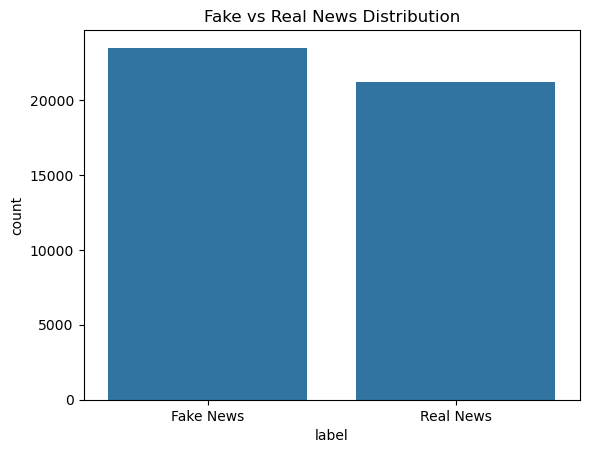

In [12]:
print("News Distribution:")
print(df['label'].value_counts())

sns.countplot(x='label', data=df)
plt.title("Fake vs Real News Distribution")
plt.xticks([0, 1], ['Fake News', 'Real News'])
plt.show()

In [13]:
df.to_csv('ISOT_Cleaned_Dataset.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [14]:
import pandas as pd
import os

df = pd.read_csv("ISOT_Cleaned_Dataset.csv")

rows_per_file = 50000

for i in range(0, len(df), rows_per_file):
    part = df.iloc[i:i+rows_per_file]
    part.to_csv(f"ISOT_Dataset_Part_{i//rows_per_file + 1}.csv",
                index=False)

print("Dataset splitting completed!")

Dataset splitting completed!


In [15]:
import os

print(os.path.getsize("ISOT_Dataset_Part_1.csv") / (1024 * 1024), "MB")

110.46636295318604 MB


In [16]:
rows_per_file = 5000

for i in range(0, len(df), rows_per_file):
    part = df.iloc[i:i+rows_per_file]
    part.to_csv(
        f"ISOT_Small_Part_{i//rows_per_file + 1}.csv",
        index=False
    )

print("Small parts created successfully!")

Small parts created successfully!


In [17]:
import glob
import os

for file in glob.glob("ISOT_Small_Part_*.csv"):
    size = os.path.getsize(file) / (1024 * 1024)
    print(file, ":", round(size, 2), "MB")

ISOT_Small_Part_1.csv : 12.44 MB
ISOT_Small_Part_2.csv : 12.23 MB
ISOT_Small_Part_3.csv : 12.46 MB
ISOT_Small_Part_4.csv : 12.3 MB
ISOT_Small_Part_5.csv : 12.27 MB
ISOT_Small_Part_6.csv : 12.47 MB
ISOT_Small_Part_7.csv : 12.39 MB
ISOT_Small_Part_8.csv : 12.29 MB
ISOT_Small_Part_9.csv : 11.63 MB
